<a href="https://colab.research.google.com/github/kylevalibia/IDX-Exchange-Data-Science/blob/main/06_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Read data from Google Drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)
path = "/content/drive/MyDrive/IDX Exchange Internship Fall 2026/Data/"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Mounted at /content/drive


In [2]:
# Dataset from middle of Notebook 4, without engineered features
x_train_pre = pd.read_csv(path + "pre_features_x_train.csv", low_memory=False)
x_valid_pre = pd.read_csv(path + "pre_features_x_valid.csv", low_memory=False)
x_test_pre = pd.read_csv(path + "pre_features_x_test.csv", low_memory=False)

# Dataset from end of Notebook 4, contains all engineered features
x_train = pd.read_csv(path + "x_train_feat.csv", low_memory=False)
x_valid = pd.read_csv(path + "x_valid_feat.csv", low_memory=False)
x_test = pd.read_csv(path + "x_test_feat.csv", low_memory=False)

y_train = pd.read_csv(path + "actual_train_vals.csv", low_memory=False)
y_valid = pd.read_csv(path + "actual_valid_vals.csv", low_memory=False)
y_test = pd.read_csv(path + "actual_test_vals.csv", low_memory=False)

results = pd.read_csv(path + "04_results.csv", low_memory=False)

# Calculating Metrics


In [98]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

baseline_result = ["First Linear Regression Model", 0.799452, "16.06%", "11.48%", "$416149.47", "$207529.13"]

metrics_summary = pd.DataFrame({"Model": [],
                                "R2": [],
                                "MAPE": [],
                                "MdAPE": [],
                                "RMSE": [],
                                "MAE": []})

metrics_summary.loc[len(metrics_summary)] = baseline_result

def linear_regression(x_train, y_train, x_eval, actual_close, name):
  model = LinearRegression()
  model.fit(x_train, np.log(y_train))
  pred_dollars = np.exp(model.predict(x_eval))
  actual_dollars = np.asarray(actual_close)

  r2 = r2_score(actual_dollars, pred_dollars)
  rmse = "$" + str(round(np.sqrt(mean_squared_error(actual_dollars, pred_dollars)), 2))
  mae = "$" + str(round(mean_absolute_error(actual_dollars, pred_dollars), 2))

  pct_err = np.abs(actual_dollars - pred_dollars) / actual_dollars * 100
  mape = str(round(pct_err.mean(), 2)) + "%"
  mdape = str(round(np.median(pct_err), 2)) + "%"

  return [name, r2, mape, mdape, rmse, mae]

d_tree = DecisionTreeRegressor(max_depth=12, min_samples_leaf=20, random_state=0)

def decision_tree(model, x_train, y_train_dollars, x_eval, actual_close, name):
  model.fit(x_train, np.log(y_train_dollars))
  pred_dollars = np.exp(model.predict(x_eval))
  actual_dollars = np.asarray(actual_close).ravel()

  r2 = r2_score(actual_dollars, pred_dollars)
  rmse = "$" + str(round(np.sqrt(mean_squared_error(actual_dollars, pred_dollars)), 2))
  mae = "$" + str(round(mean_absolute_error(actual_dollars, pred_dollars), 2))

  pct_err = np.abs(actual_dollars - pred_dollars) / actual_dollars * 100
  mape = str(round(pct_err.mean(), 2)) + "%"
  mdape = str(round(np.median(pct_err), 2)) + "%"

  return [name, r2, mape, mdape, rmse, mae]

rf = RandomForestRegressor(n_estimators=200, max_depth=20, min_samples_leaf=2, max_features=0.5, n_jobs=-1, random_state=0)

def random_forest(model, x_train, y_train_dollars, x_eval, actual_close, name):
  model.fit(x_train, np.log(y_train_dollars))
  pred_dollars = np.exp(model.predict(x_eval))
  actual_dollars = np.asarray(actual_close).ravel()

  r2 = r2_score(actual_dollars, pred_dollars)
  rmse = "$" + str(round(np.sqrt(mean_squared_error(actual_dollars, pred_dollars)), 2))
  mae = "$" + str(round(mean_absolute_error(actual_dollars, pred_dollars), 2))

  pct_err = np.abs(actual_dollars - pred_dollars) / actual_dollars * 100
  mape = str(round(pct_err.mean(), 2)) + "%"
  mdape = str(round(np.median(pct_err), 2)) + "%"

  return [name, r2, mape, mdape, rmse, mae]

xgb = XGBRegressor(n_estimators=800, max_depth=6, learning_rate=0.05, subsample=0.5, colsample_bytree=0.8, tree_method="hist", n_jobs=-1, random_state=0)

def xgboost(params, x_train, y_train, x_eval, y_eval, name):
  model = params
  model.fit(x_train, np.log(y_train))
  pred_dollars = np.exp(model.predict(x_eval))
  actual_dollars = np.asarray(y_eval).ravel()

  r2 = r2_score(actual_dollars, pred_dollars)
  rmse = "$" + str(round(np.sqrt(mean_squared_error(actual_dollars, pred_dollars)), 2))
  mae = "$" + str(round(mean_absolute_error(actual_dollars, pred_dollars), 2))

  pct_err = np.abs(actual_dollars - pred_dollars) / actual_dollars * 100
  mape = str(round(pct_err.mean(), 2)) + "%"
  mdape = str(round(np.median(pct_err), 2)) + "%"

  return [name, r2, mape, mdape, rmse, mae]

In [35]:
metrics_summary.loc[len(metrics_summary)] = linear_regression(x_train_pre, y_train, x_test_pre, y_test, "Linear Regression v2")
metrics_summary.loc[len(metrics_summary)] = decision_tree(d_tree, x_train_pre, y_train, x_test_pre, y_test, "Decision Tree")
metrics_summary.loc[len(metrics_summary)] = random_forest(rf, x_train_pre, y_train, x_test_pre, y_test, "Random Forest")

metrics_summary.loc[len(metrics_summary)] = linear_regression(x_train, y_train, x_test, y_test, "Linear Regression w/ Feats.")
metrics_summary.loc[len(metrics_summary)] = decision_tree(d_tree, x_train, y_train, x_test, y_test, "Decision Tree w/ Feats.")
metrics_summary.loc[len(metrics_summary)] = random_forest(rf, x_train, y_train, x_test, y_test, "Random Forest w/ Feats.")

metrics_summary.loc[len(metrics_summary)] = xgboost(xgb, x_train, y_train, x_test, y_test, "XGBoost w/ Feats.")

display(metrics_summary)

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


,Model,R2,MAPE,MdAPE,RMSE,MAE
0,First Linear Regression Model,0.799452,16.06%,11.48%,$416149.47,$207529.13
1,Linear Regression v2,0.788188,17.82%,12.91%,$440411.92,$230701.63
2,Decision Tree,0.822139,15.45%,10.41%,$403575.11,$204568.64
3,Random Forest,0.862612,12.82%,8.56%,$354698.06,$173894.1
4,Linear Regression w/ Feats.,0.790414,17.4%,12.72%,$438091.29,$227364.22
5,Decision Tree w/ Feats.,0.821981,15.39%,10.6%,$403754.57,$205603.37
6,Random Forest w/ Feats.,0.872468,12.31%,8.34%,$341737.84,$166830.6
7,XGBoost w/ Feats.,0.887355,12.17%,8.53%,$321173.05,$161964.12


# XGB Price Bands

In [67]:
pred = np.exp(xgb.predict(x_test))
actual = np.asarray(y_test).ravel()

df = pd.DataFrame({"actual": actual, "pred": pred})
df["abs_err"] = (df["actual"] - df["pred"]).abs()
df["pct_err"] = df["abs_err"] / df["actual"] * 100
df["signed_pct"] = (df["pred"] - df["actual"]) / df["actual"] * 100

bins = [0, 500_000, 1_000_000, 1_500_000, 2_500_000, np.inf]
labels = ["<$500k", "$500k-1M", "$1M-1.5M", "$1.5M-2.5M", "$2.5M+"]
df["band"] = pd.cut(df["actual"], bins=bins, labels=labels)

xgb_by_band = df.groupby("band", observed=True).agg(
    n=("actual", "size"),
    MdAPE=("pct_err", "median"),
    MAPE=("pct_err", "mean"),
    MAE=("abs_err", "mean"),
    RMSE=("abs_err", lambda s: np.sqrt((s**2).mean())),
    median_bias_pct=("signed_pct", "median"),
)
display(xgb_by_band.round(2))

,n,MdAPE,MAPE,MAE,RMSE,median_bias_pct
band,,,,,,
<$500k,1728,8.44,15.05,54578.72,94392.63,2.82
$500k-1M,5106,6.83,9.80,72826.78,109301.54,-0.78
$1M-1.5M,2401,9.34,11.97,148006.32,221450.29,-3.26
$1.5M-2.5M,1879,10.93,13.76,261779.40,350135.04,-5.52
$2.5M+,991,14.14,16.85,653040.80,911944.98,-10.51


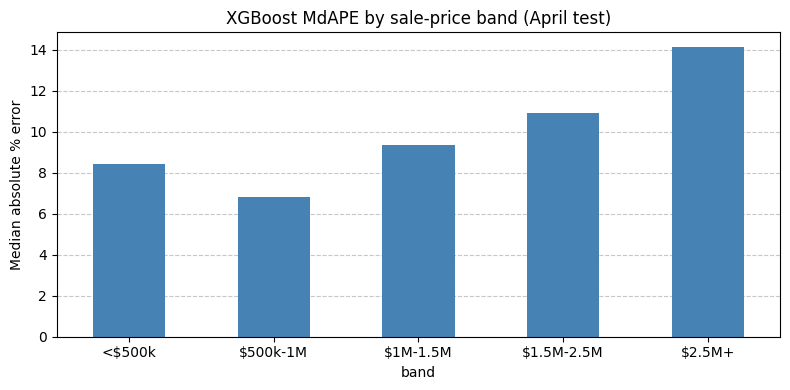

In [113]:
ax = xgb_by_band["MdAPE"].plot(kind="bar", figsize=(8, 4), color="steelblue", rot=0)
ax.set_ylabel("Median absolute % error")
ax.set_title("XGBoost MdAPE by sale-price band (April test)")
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

# Random Forest Price Bands

In [63]:
pred = np.exp(rf.predict(x_test))
actual = np.asarray(y_test).ravel()

df = pd.DataFrame({"actual": actual, "pred": pred})
df["abs_err"] = (df["actual"] - df["pred"]).abs()
df["pct_err"] = df["abs_err"] / df["actual"] * 100
df["signed_pct"] = (df["pred"] - df["actual"]) / df["actual"] * 100

bins = [0, 500_000, 1_000_000, 1_500_000, 2_500_000, np.inf]
labels = ["<$500k", "$500k-1M", "$1M-1.5M", "$1.5M-2.5M", "$2.5M+"]
df["band"] = pd.cut(df["actual"], bins=bins, labels=labels)

rf_by_band = df.groupby("band", observed=True).agg(
    n=("actual", "size"),
    MdAPE=("pct_err", "median"),
    MAPE=("pct_err", "mean"),
    MAE=("abs_err", "mean"),
    RMSE=("abs_err", lambda s: np.sqrt((s**2).mean())),
    median_bias_pct=("signed_pct", "median"),
)
display(rf_by_band.round(2))

,n,MdAPE,MAPE,MAE,RMSE,median_bias_pct
band,,,,,,
<$500k,1728,7.99,15.81,56605.42,107351.98,3.37
$500k-1M,5106,6.49,9.56,71033.55,107790.30,-0.57
$1M-1.5M,2401,9.11,11.90,147104.61,220931.59,-3.10
$1.5M-2.5M,1879,11.00,14.09,267855.49,364534.35,-5.66
$2.5M+,991,14.84,17.95,708854.00,988099.60,-12.36


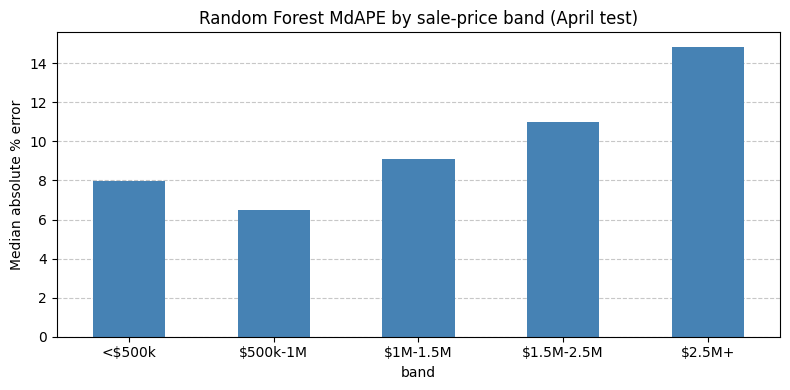

In [112]:
ax = rf_by_band["MdAPE"].plot(kind="bar", figsize=(8, 4), color="steelblue", rot=0)
ax.set_ylabel("Median absolute % error")
ax.set_title("Random Forest MdAPE by sale-price band (April test)")
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

# Decision Tree Price Bands

In [65]:
pred = np.exp(d_tree.predict(x_test))
actual = np.asarray(y_test).ravel()

df = pd.DataFrame({"actual": actual, "pred": pred})
df["abs_err"] = (df["actual"] - df["pred"]).abs()
df["pct_err"] = df["abs_err"] / df["actual"] * 100
df["signed_pct"] = (df["pred"] - df["actual"]) / df["actual"] * 100

bins = [0, 500_000, 1_000_000, 1_500_000, 2_500_000, np.inf]
labels = ["<$500k", "$500k-1M", "$1M-1.5M", "$1.5M-2.5M", "$2.5M+"]
df["band"] = pd.cut(df["actual"], bins=bins, labels=labels)

dt_by_band = df.groupby("band", observed=True).agg(
    n=("actual", "size"),
    MdAPE=("pct_err", "median"),
    MAPE=("pct_err", "mean"),
    MAE=("abs_err", "mean"),
    RMSE=("abs_err", lambda s: np.sqrt((s**2).mean())),
    median_bias_pct=("signed_pct", "median"),
)
display(dt_by_band.round(2))

,n,MdAPE,MAPE,MAE,RMSE,median_bias_pct
band,,,,,,
<$500k,1728,10.97,19.44,70316.78,125483.46,5.62
$500k-1M,5106,8.55,12.37,92071.47,140471.98,0.12
$1M-1.5M,2401,11.18,14.81,182972.60,265561.44,-3.40
$1.5M-2.5M,1879,12.70,17.20,327049.29,455925.08,-5.64
$2.5M+,991,19.06,21.82,851020.78,1138917.27,-14.68


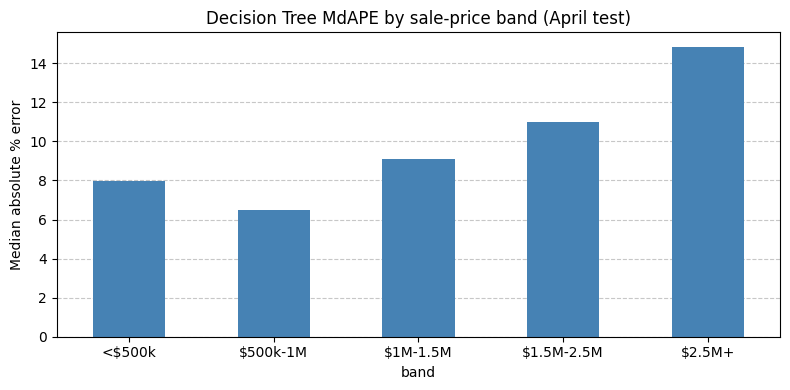

In [111]:
ax = rf_by_band["MdAPE"].plot(kind="bar", figsize=(8, 4), color="steelblue", rot=0)
ax.set_ylabel("Median absolute % error")
ax.set_title("Decision Tree MdAPE by sale-price band (April test)")
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

# Linear Regression Price Bands

In [76]:
lin = LinearRegression()
lin.fit(x_train, np.log(y_train))

pred = np.exp(lin.predict(x_test)).ravel()
actual = np.asarray(y_test).ravel()

df = pd.DataFrame({"actual": actual, "pred": pred})
df["abs_err"] = (df["actual"] - df["pred"]).abs()
df["pct_err"] = df["abs_err"] / df["actual"] * 100
df["signed_pct"] = (df["pred"] - df["actual"]) / df["actual"] * 100

bins = [0, 500_000, 1_000_000, 1_500_000, 2_500_000, np.inf]
labels = ["<$500k", "$500k-1M", "$1M-1.5M", "$1.5M-2.5M", "$2.5M+"]
df["band"] = pd.cut(df["actual"], bins=bins, labels=labels)

lr_by_band = df.groupby("band", observed=True).agg(
    n=("actual", "size"),
    MdAPE=("pct_err", "median"),
    MAPE=("pct_err", "mean"),
    MAE=("abs_err", "mean"),
    RMSE=("abs_err", lambda s: np.sqrt((s**2).mean())),
    median_bias_pct=("signed_pct", "median"),
)
display(lr_by_band.round(2))

,n,MdAPE,MAPE,MAE,RMSE,median_bias_pct
band,,,,,,
<$500k,1728,13.12,22.73,82930.89,142181.42,4.16
$500k-1M,5106,11.43,15.24,112542.79,158686.13,-1.09
$1M-1.5M,2401,11.86,15.00,185326.23,255518.45,-4.06
$1.5M-2.5M,1879,14.47,17.66,337221.19,440759.65,-9.57
$2.5M+,991,22.00,24.60,964368.19,1285618.49,-19.50


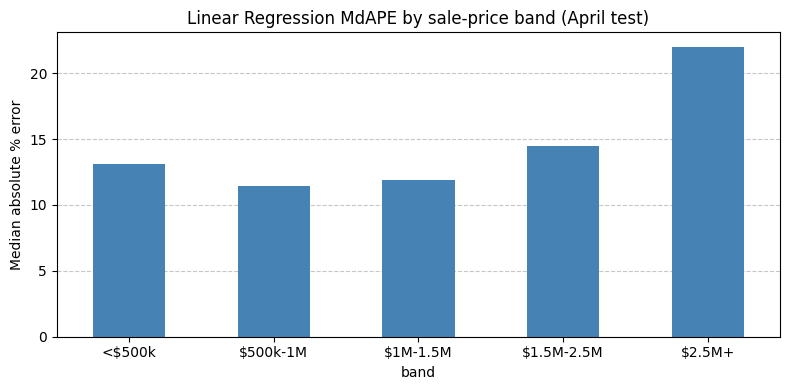

In [110]:
ax = lr_by_band["MdAPE"].plot(kind="bar", figsize=(8, 4), color="steelblue", rot=0)
ax.set_ylabel("Median absolute % error")
ax.set_title("Linear Regression MdAPE by sale-price band (April test)")
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

# Final Insights

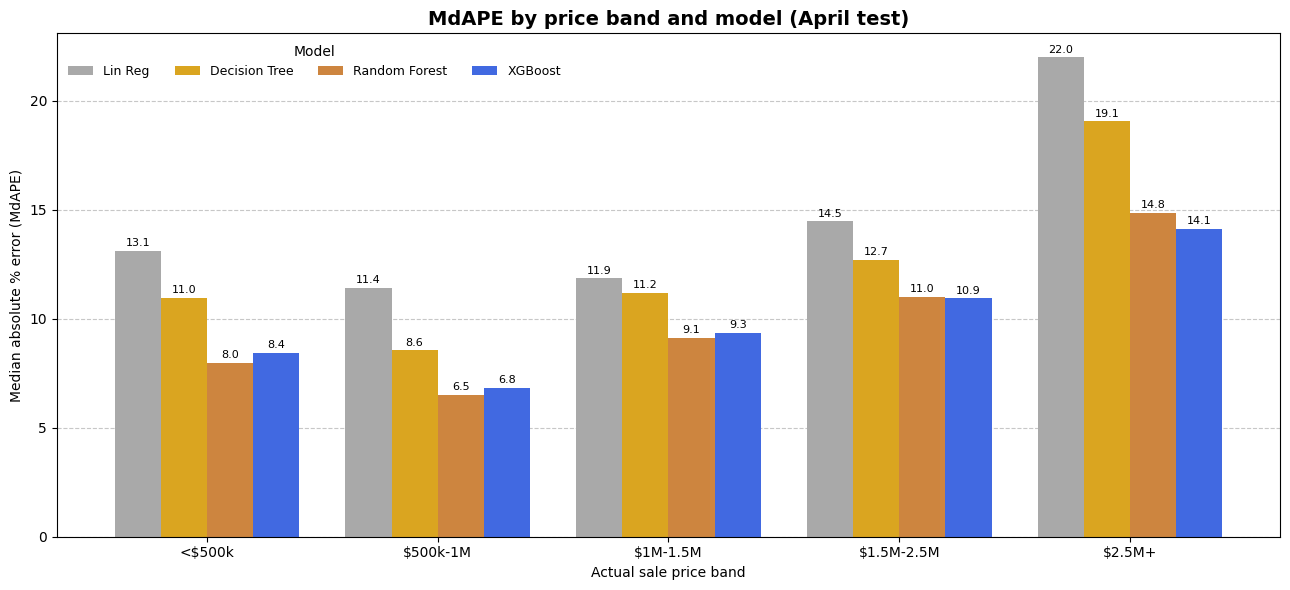

In [115]:
combined = pd.DataFrame({"Lin Reg": lr_by_band["MdAPE"],
                         "Decision Tree": dt_by_band['MdAPE'],
                         "Random Forest": rf_by_band["MdAPE"],
                         "XGBoost": xgb_by_band["MdAPE"]})

colors = ["darkgrey", "goldenrod", "peru", "royalblue"]

fig, ax = plt.subplots(figsize=(13, 6))
combined.plot(kind="bar", ax=ax, width=0.8, rot=0, color=colors)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", fontsize=8, padding=2)

ax.set_ylabel("Median absolute % error (MdAPE)")
ax.set_xlabel("Actual sale price band")
ax.set_title("MdAPE by price band and model (April test)", fontsize=14, weight="bold")
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=9, ncol=4, title="Model", loc="upper left")
plt.tight_layout()
plt.show()